In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from matplotlib.animation import FuncAnimation

# Activation function (step function)
def activate(y):
    return np.where(y > 0, 1, 0)

# Perceptron class
class Perceptron:
    def __init__(self, lr=0.1, n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.activation_func = activate
        self.weights = None
        self.bias = None
        self.history = []  # To store decision boundary details for visualization

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)  # Initialize weights as zeros
        self.bias = 0

        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                # Linear output
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_pred = self.activation_func(linear_output)

                # Perceptron update rule
                update = self.lr * (y[idx] - y_pred)
                self.weights += update * x_i
                self.bias += update

            # Store weights and bias for visualization
            self.history.append((self.weights.copy(), self.bias))

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.activation_func(linear_output)  # Step function for binary output


In [2]:
# Plot decision boundary history function
def plot_decision_boundary_history(X, y, model, scaler):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    
    # Transform grid before passing to the model
    grid_transformed = grid  # No polynomial features in this case

    fig, ax = plt.subplots(figsize=(8, 6))

    def update(frame):
        ax.clear()
        
        # Get the weights and bias at the current epoch
        weights, bias = model.history[frame]
        
        # Compute the decision boundary
        linear_output = np.dot(grid_transformed, weights) + bias
        Z = activate(linear_output).reshape(xx.shape)
        
        # Plot the contour and the data points
        ax.contourf(xx, yy, Z, alpha=0.8, cmap='coolwarm')
        ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
        ax.set_title(f"Decision Boundary at Epoch {frame + 1}")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")
    
    # Create the animation
    anim = FuncAnimation(fig, update, frames=len(model.history), interval=100)
    
    # Save the animation as a video
    anim.save("decision_boundary_animation.gif", writer="pillow", fps=1)

    plt.show()


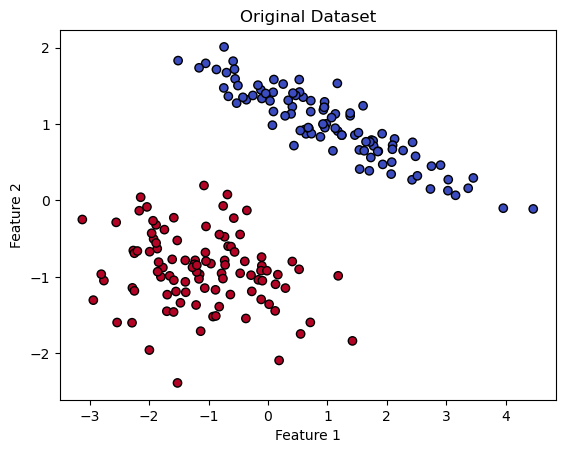

Training Accuracy: 100.00%
Testing Accuracy: 100.00%


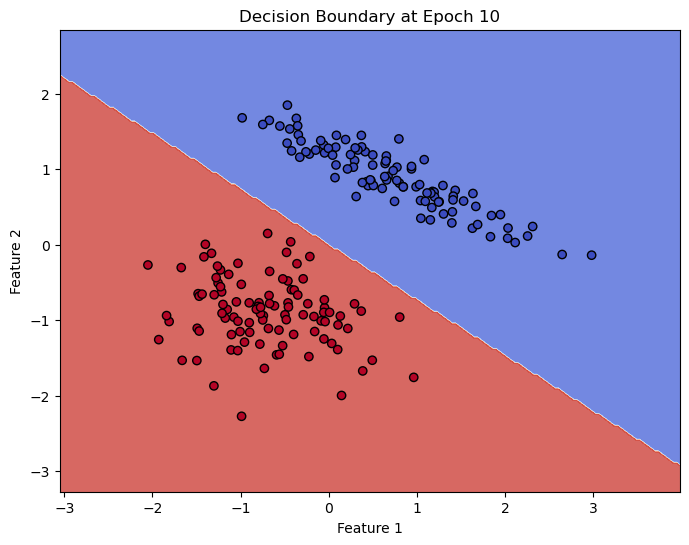

In [3]:
# Load data
X = np.load('Xlin_sep.npy')
y = np.load('ylin_sep.npy')

# Ensure labels are binary (convert -1 to 0)
y = np.where(y == -1, 0, y)

# Visualize the original dataset
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data into training and testing sets
X_train, X_test = X[:50], X[50:]
y_train, y_test = y[:50], y[50:]

# Initialize and train the Perceptron
model = Perceptron(lr=0.1, n_iters=10)
model.fit(X_train, y_train)

# Predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate accuracy
train_accuracy = np.mean(train_predictions == y_train) * 100
test_accuracy = np.mean(test_predictions == y_test) * 100

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Testing Accuracy: {test_accuracy:.2f}%")

# Plot the decision boundary and create the animation
plot_decision_boundary_history(X, y, model, scaler)

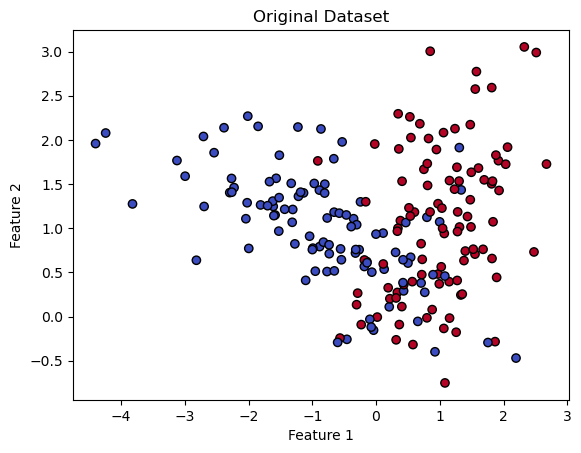

Training Accuracy: 74.00%
Testing Accuracy: 85.33%


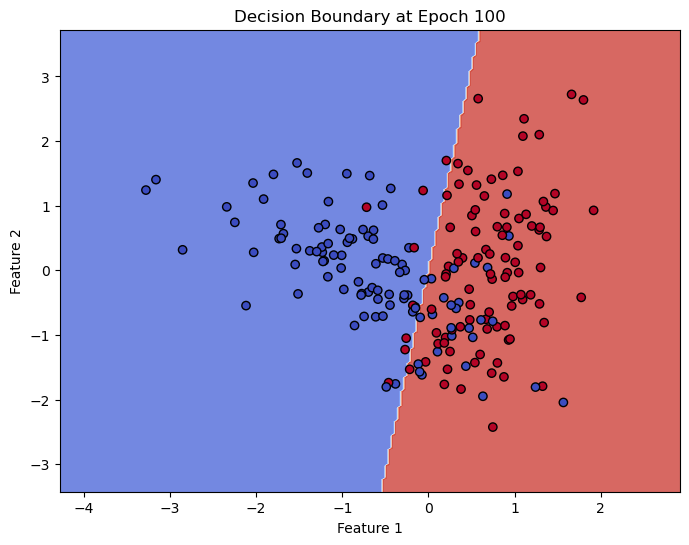

In [4]:
# Load data
X = np.load('Xlinnoise_sep.npy')
y = np.load('ylinnoise_sep.npy')

# Ensure labels are binary (convert -1 to 0)
y = np.where(y == -1, 0, y)

# Visualize the original dataset
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data into training and testing sets
X_train, X_test = X[:50], X[50:]
y_train, y_test = y[:50], y[50:]

# Initialize and train the Perceptron
model = Perceptron(lr=0.1, n_iters=100)
model.fit(X_train, y_train)

# Predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate accuracy
train_accuracy = np.mean(train_predictions == y_train) * 100
test_accuracy = np.mean(test_predictions == y_test) * 100

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Testing Accuracy: {test_accuracy:.2f}%")

# Plot the decision boundary and create the animation
plot_decision_boundary_history(X, y, model, scaler)

In [5]:
def plot_decision_boundary_history(X, y, model, poly, scaler):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    
    # Transform grid using the same polynomial features as the training data
    grid_transformed = poly.transform(scaler.transform(grid))

    fig, ax = plt.subplots(figsize=(8, 6))

    def update(frame):
        ax.clear()
        
        # Get the weights and bias at the current epoch
        weights, bias = model.history[frame]
        
        # Compute the decision boundary
        linear_output = np.dot(grid_transformed, weights) + bias
        Z = activate(linear_output).reshape(xx.shape)
        
        # Plot the contour and the data points
        ax.contourf(xx, yy, Z, alpha=0.8, cmap='coolwarm')
        ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
        ax.set_title(f"Decision Boundary at Epoch {frame + 1}")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")
    
    # Create the animation
    anim = FuncAnimation(fig, update, frames=len(model.history), interval=100)
    
    # Save the animation as a video
    anim.save("decision_boundary_animation.gif", writer="pillow", fps=1)

    plt.show()


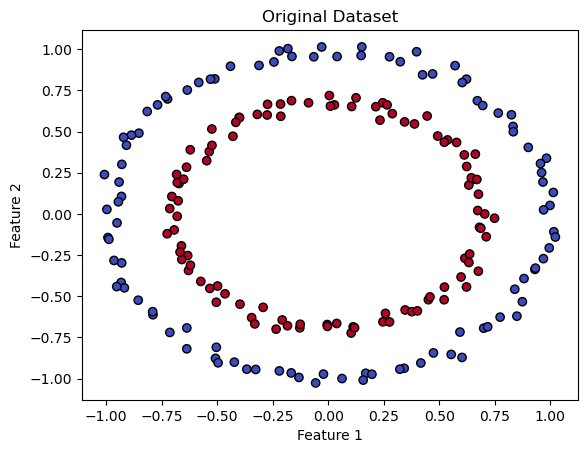

Training Accuracy: 100.00%
Testing Accuracy: 99.33%


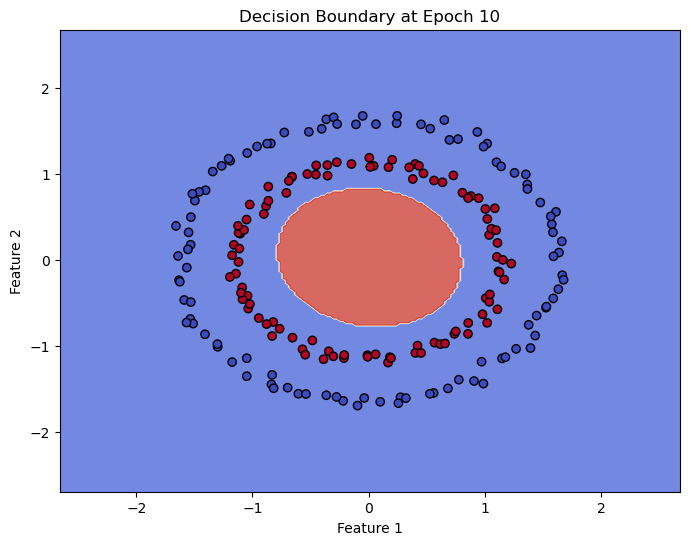

In [6]:
# Load data
X = np.load('circles_x.npy')
y = np.load('circles_y.npy')

# Ensure labels are binary (convert -1 to 0)
y = np.where(y == -1, 0, y)

# Visualize the original dataset
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Polynomial feature expansion
poly = PolynomialFeatures(degree=2, include_bias=False)
X = poly.fit_transform(X)

# Split data into training and testing sets
X_train, X_test = X[:50], X[50:]
y_train, y_test = y[:50], y[50:]

# Initialize and train the Perceptron
model = Perceptron(lr=0.1, n_iters=10)
model.fit(X_train, y_train)

# Predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate accuracy
train_accuracy = np.mean(train_predictions == y_train) * 100
test_accuracy = np.mean(test_predictions == y_test) * 100

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Testing Accuracy: {test_accuracy:.2f}%")

# Plot the decision boundary and create the animation
plot_decision_boundary_history(X, y, model, poly, scaler)

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score


# Step 1: Load the MNIST Digits Dataset (using load_digits for this example)
digits = load_digits()
X = digits.data
y = digits.target

# Step 2: Split the data into training and testing sets (20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Set up k-fold Cross-Validation (k = 5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Step 4: Define the hyperparameter grid for MLPClassifier
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (150,), (100, 50)],
    'activation': ['relu', 'tanh', 'logistic'],
    'solver': ['adam', 'sgd'],
    'learning_rate': ['constant', 'invscaling', 'adaptive'],
    'learning_rate_init': [0.001, 0.01, 0.1],
}

# Step 5: Set up Randomized Search with cross-validation
mlp = MLPClassifier(max_iter=1000, random_state=42)
random_search = RandomizedSearchCV(mlp, param_grid, n_iter=20, cv=kf, random_state=42, n_jobs=-1)

# Fit the RandomizedSearchCV object
random_search.fit(X_train, y_train)

# Step 6: Report the best hyperparameters found by the random search
print(f"Best Hyperparameters: {random_search.best_params_}")

# Step 7: Evaluate the model on the test set
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

# Optional: Cross-validation score on the entire dataset (without the test set)
cv_scores = cross_val_score(best_model, X, y, cv=kf)
print(f"Cross-validation scores: {cv_scores}")
print(f"Average cross-validation score: {np.mean(cv_scores):.4f}")


/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Best Hyperparameters: {'solver': 'adam', 'learning_rate_init': 0.01, 'learning_rate': 'constant', 'hidden_layer_sizes': (150,), 'activation': 'logistic'}
Test Accuracy: 0.9806
Cross-validation scores: [0.97777778 0.98333333 0.97214485 0.98050139 0.96657382]
Average cross-validation score: 0.9761
